# ♟️ Chess Numba — NMP 離散參數驗證錦標賽 (Colab Runner)

本 Notebook 用於在 Google Colab 雲端高並行環境下，針對 **NMP 離散小整數參數** 進行成對換先（Color-swapped Pairs）LTC 錦標賽對戰驗證：

### 🎯 本輪對抗設定 (Round 1: Verification Depth)
* **Engine 1 (New / Candidate)**: `chess_engine/classical` (`NMP_VERIFICATION_DEPTH = 14`)
* **Engine 2 (Old / Baseline)**: `chess_engine/classical_old` (`NMP_VERIFICATION_DEPTH = 16`，SF19 原生基準)
* **時控規範**: 300,000 nodes（長時控深度視野，平均 depth 18~20）
* **對戰規模**: 400 局（200 對換先開局配對），64MB 轉置表，開局庫 `data/openings.epd`
* **檢驗核心**: 檢驗在 $d=14\sim 15$ 層啟動輕量驗證搜尋（Verification Search），能否在幾乎不增加節點開銷的前提下，為複雜中局提供更強的防 Zugzwang / 防棄子防護網。


In [1]:
# 1. 檢視 Colab 雲端硬體與 CPU 核心數
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.3Gi        47Gi       2.2Mi       3.2Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.16


In [2]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content
Cloning into 'chess_numba'...
remote: Enumerating objects: 3778, done.
remote: Counting objects: 100% (516/516), done.
remote: Compressing objects: 100% (318/318), done.
remote: Total 3778 (delta 391), reused 304 (delta 198), pack-reused 3262 (from 1)
Receiving objects: 100% (3778/3778), 176.90 MiB | 34.75 MiB/s, done.
Resolving deltas: 100% (2614/2614), done.
/content/chess_numba
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
Already on 'feat-initial-bitboard-setup'
Your branch is up to date with 'origin/feat-initial-bitboard-setup'.
HEAD is now at c353f73 維持MIN_SINGULAR_DEPTH = 9並移除(+ (1 if tt_pv else 0))，進行對戰
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 79.2 MB/s eta 0:00:00:00:010:01
  Preparing metadata (setup.py) ... done

🎉 環境與相依套件安裝完畢！


In [3]:
# =====================================================================
# 步驟 3: 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff-code

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Unchanged tuner/constants_snapshot.py
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in search.py:
--- classical_old/search.py
+++ classical/search.py
@@ -2435,7 +2435,7 @@
 
         # --- Step 15: Singular Extensions & Multi-Cut (Pre-make, move == tt_move) ---
         if (ENABLE_SINGULAR_EXTENSIONS and ply > 0 and excluded_move == NO_MOVE
-                and move == tt_move and depth >= MIN_SINGULAR_DEPTH + (1 if tt_pv else 0)
+                and move == tt_move and depth >= MIN_SINGULAR_DEPTH
                 and not is_currently_in_check and skip_post_legality_s):
             if ((tt_flag == TT_FLAG_BETA or tt_flag == TT_FLAG_EXACT)
                     and tt_depth >= depth - SINGULAR_TT_DEPTH_SLACK):

🔥 執行單元合約測試：
...................
----------------------------------------------------------------------
Ran 19 tests in 6.294s

OK


In [4]:
# =====================================================================
# 步驟 4: 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 600                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 300000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB}


♟️ 錦標賽參數配置：
  總局數: 600 局 (300 對成對換先開局)  時控: 300,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content/chess_numba
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=0
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 1 nodes 494 nps 1212 hashfull 0.0% time 407 pv e2a6
info depth 2 score cp 1 nodes 885 nps 1372 hashfull 0.0% time 644 pv e2a6 b4c3
info depth 3 score cp -34 nodes 1872 nps 2897 hashfull 0.0% time 645 pv e2a6 b4c3 d2c3
info depth 4 score cp -34 nodes 2312 nps 3575 hashfull 0.0% time 646 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -125 nodes 5826 nps 8952 hashfull 0.0% time 650 pv e2a6 b4c3 d2c3 e6d5 e4d5
info depth 6 score cp -125 nodes 6413 nps 9841 hashfull 0.0% time 651 pv e2a6 b4c3 d2c3 e6d5 e4d5 h3g2
inf

In [7]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

report_path = Path("tournament_analysis/game_stats_report.txt")
if report_path.exists():
    print("\n" + "=" * 60)
    print("📊 對戰統計結果報告 (Game Stats Report)：")
    print("=" * 60)
    print(report_path.read_text(encoding='utf-8'))

search_report_path = Path("tournament_analysis/search_stats_report.txt")
if search_report_path.exists():
    print("\n" + "=" * 60)
    print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
    print("=" * 60)
    print(search_report_path.read_text(encoding='utf-8'))


/content/chess_numba
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.10.16': 600}
White 名稱: Counter({'New': 300, 'Old': 300})
Black 名稱: Counter({'Old': 300, 'New': 300})

[1. 總體戰績與 Elo 表現]
總對局數 : 600 局
戰績統計 : 勝 143 | 和 339 | 負 118
勝率(含和) : 52.08%
和局率 : 56.50%
相對 Elo 變化 : 14.48
95% 信賴區間 : [-4.10, 33.15]
CI 單位 : color-swapped pair clustered (n=300 independent units)
  ⚖️ 尚無顯著差距（CI 含 0）


[2. 先手優勢與執色分析]
持白勝率 : 55.50% (勝:83 和:167 負:50)
持黑勝率 : 48.67% (勝:60 和:172 負:68)
賽局總體白方勝率 : 53.42%
卡方 p-value : 3.8411e-02


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - Nc3: n=15 勝率 60.00% (W5 D8 L2)
  - e4: n=11 勝率 72.73% (W6 D4 L1)
  - h3: n=10 勝率 60.00% (W4 D4 L2)
  - Nf3: n=10 勝率 40.00% (W1 D6 L3)
  - a4: n=9 勝率 61.11% (W4 D3 L2)
【持黑面對的主流開局】
  - 面對 a3: n=12 勝率 54.17% 


📈 累積分數曲線 (Cumulative Score)：


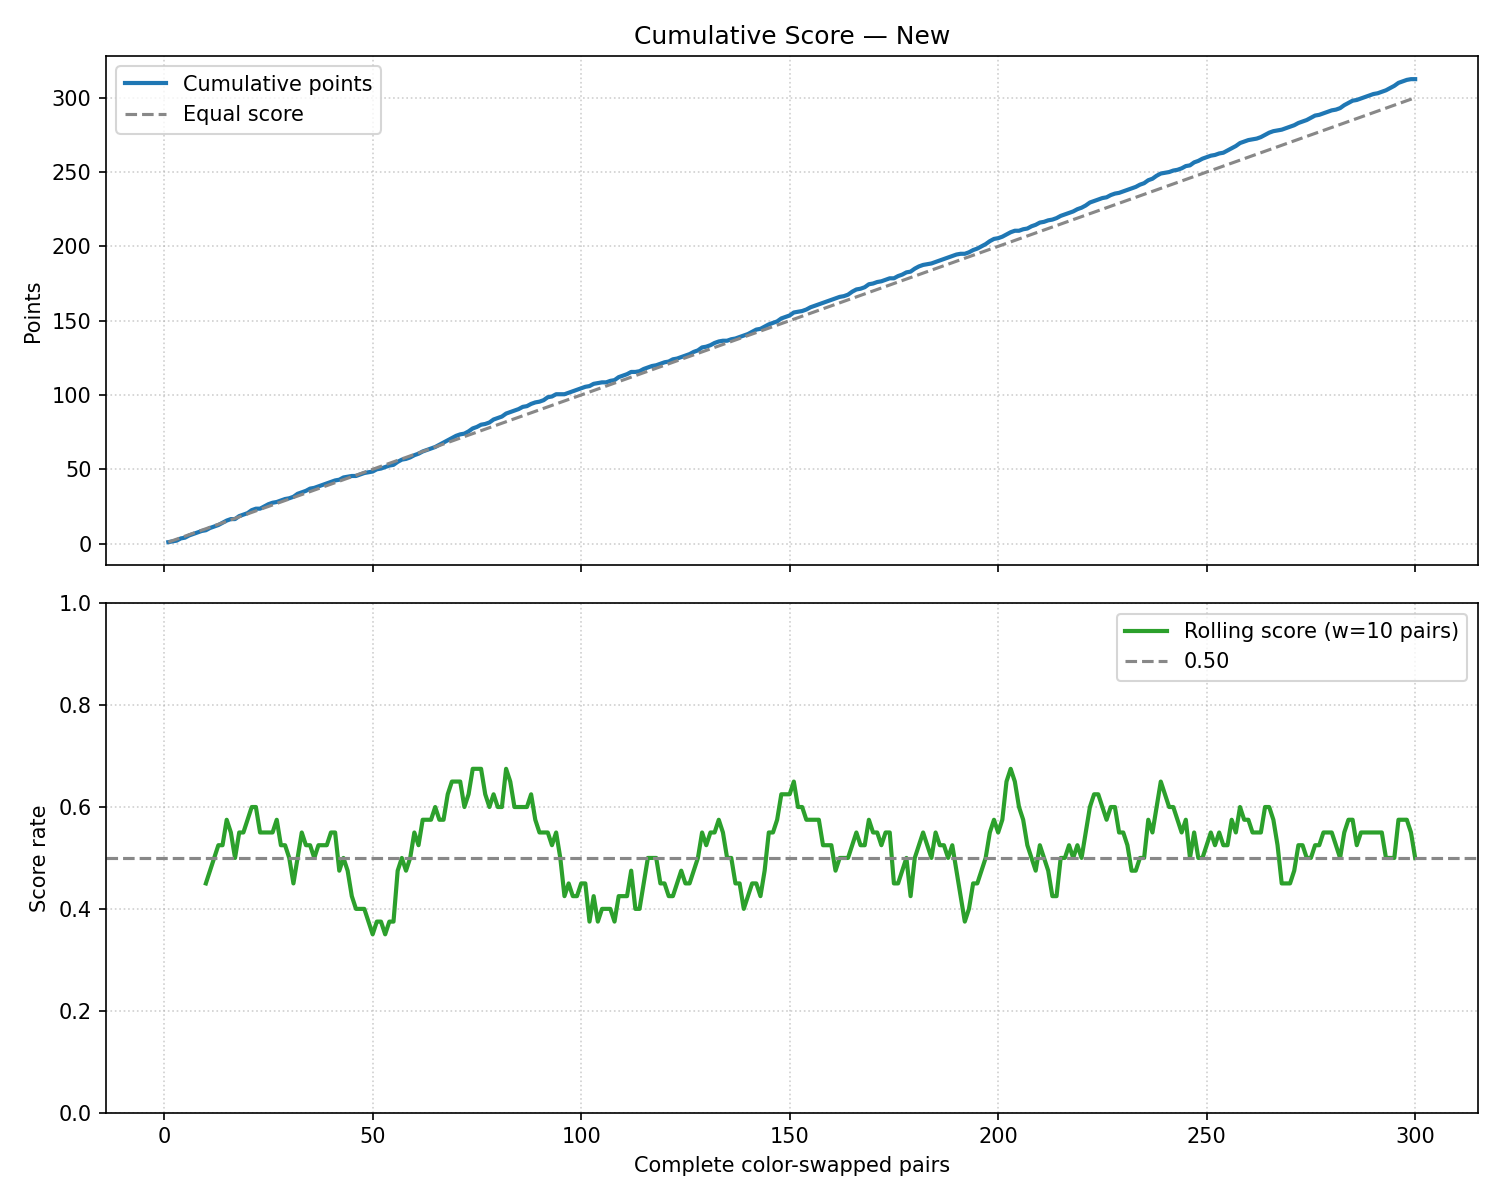


📈 Elo 置信區間收斂圖 (Elo CI)：


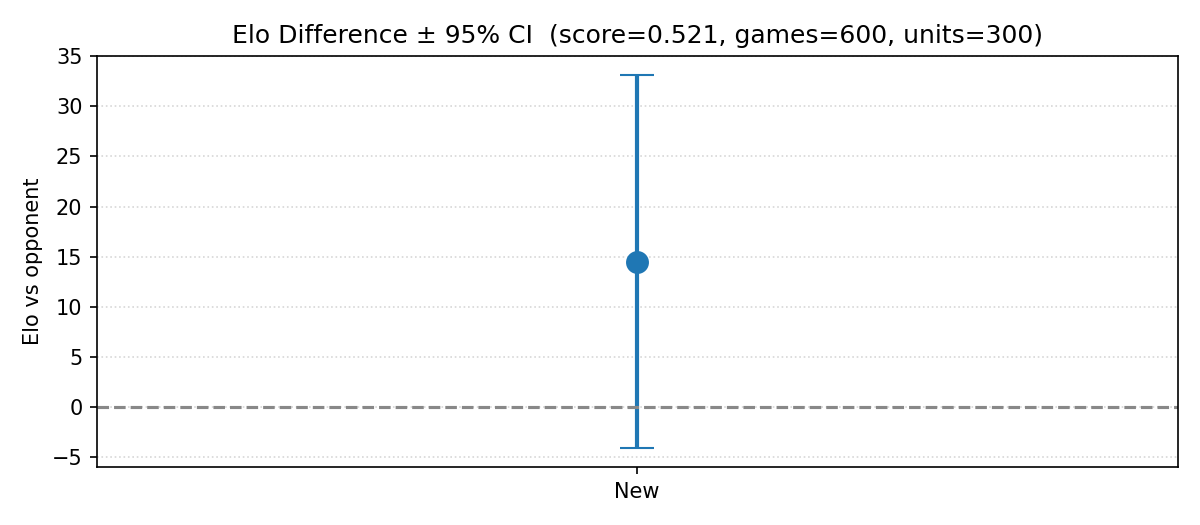


📈 每手搜尋深度 (Depth per Move)：


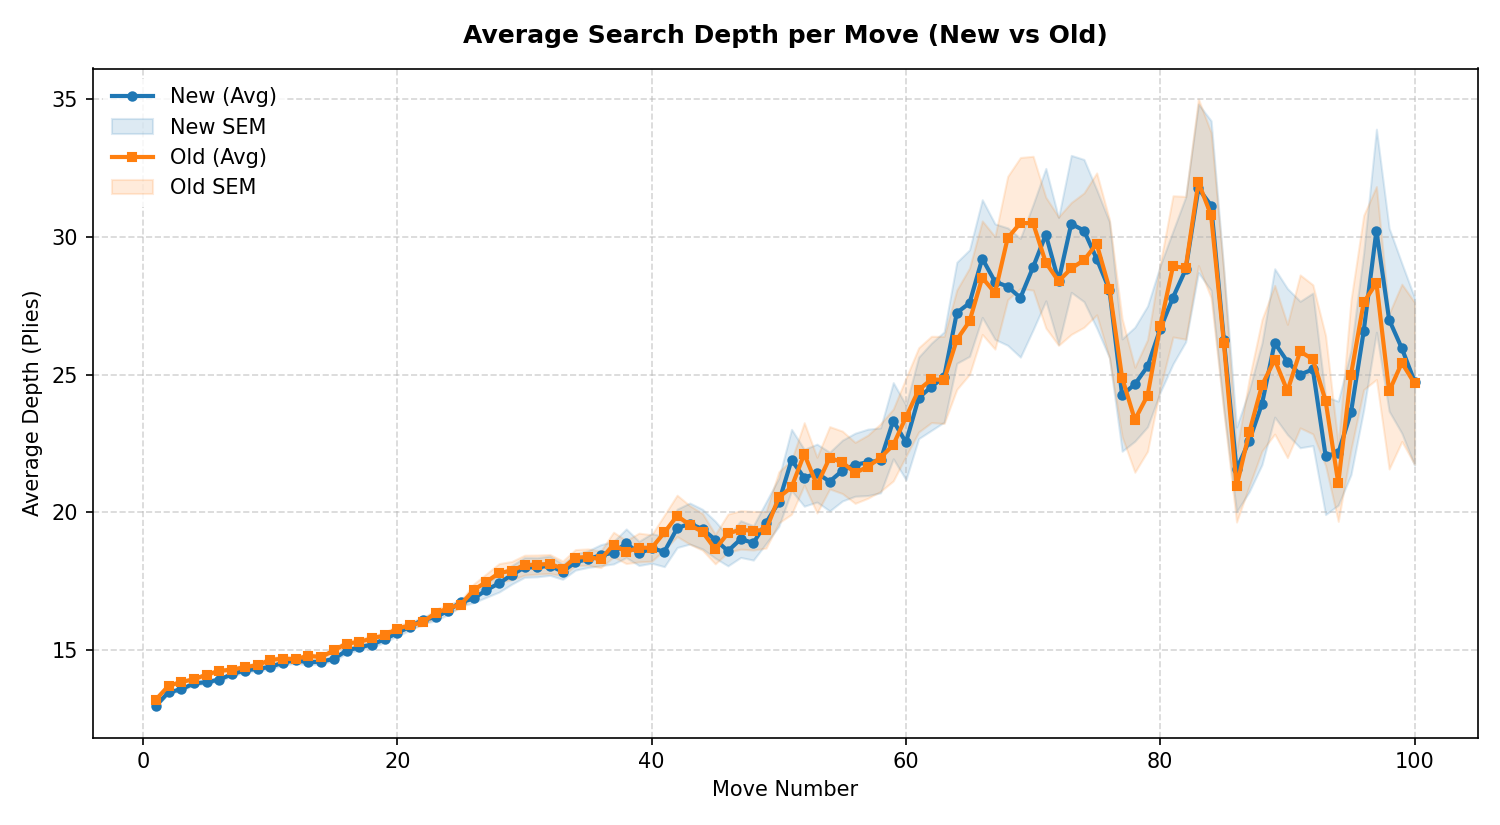


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


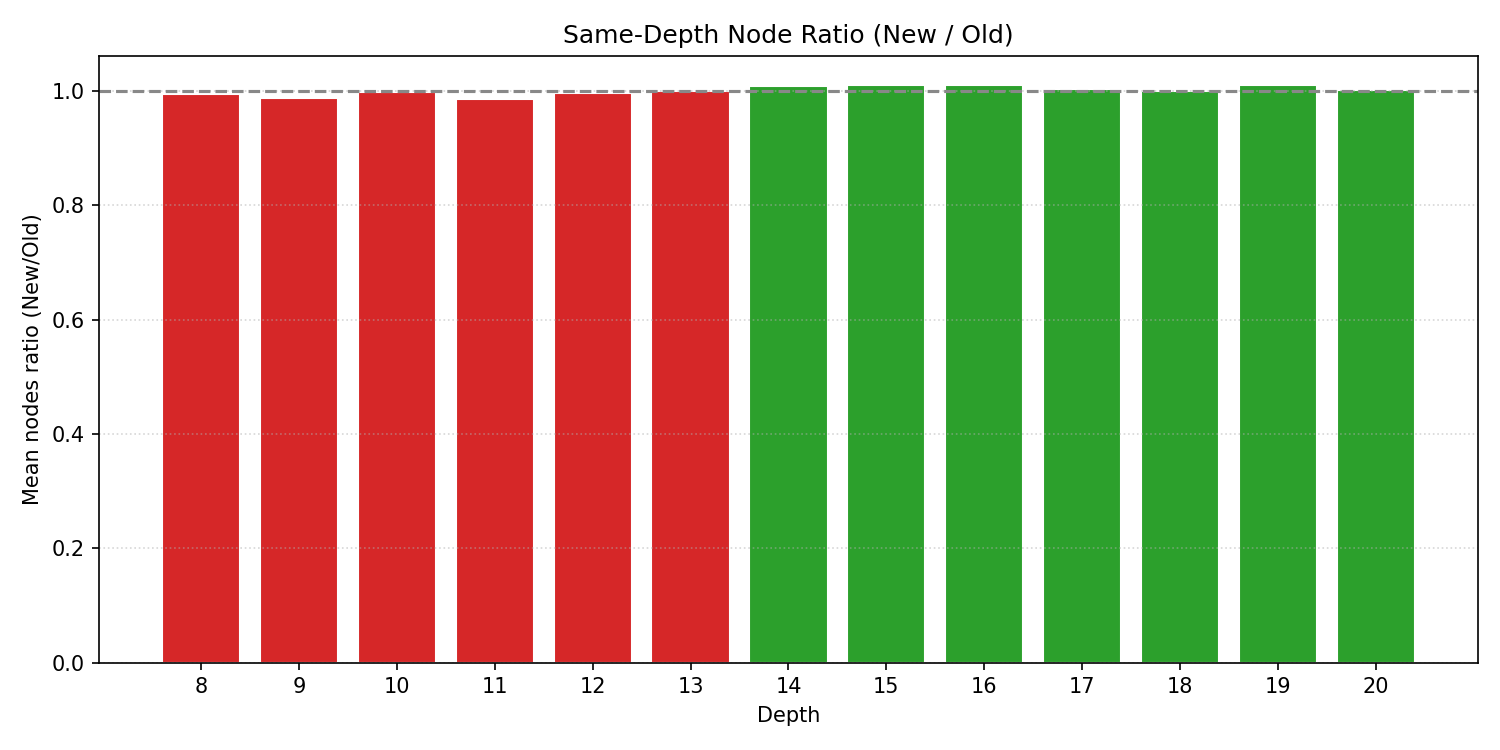


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


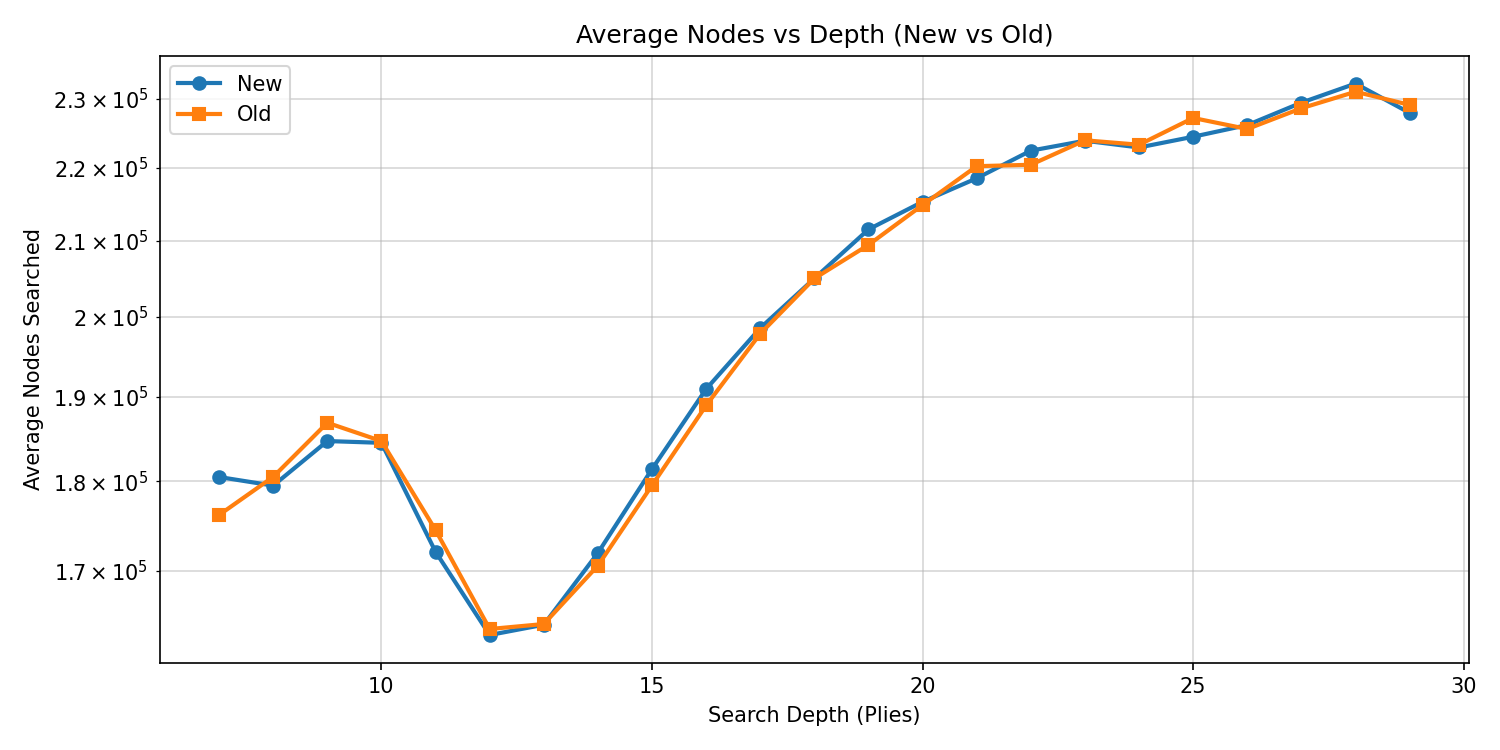


📈 黑白勝負分佈 (WDL by Color)：


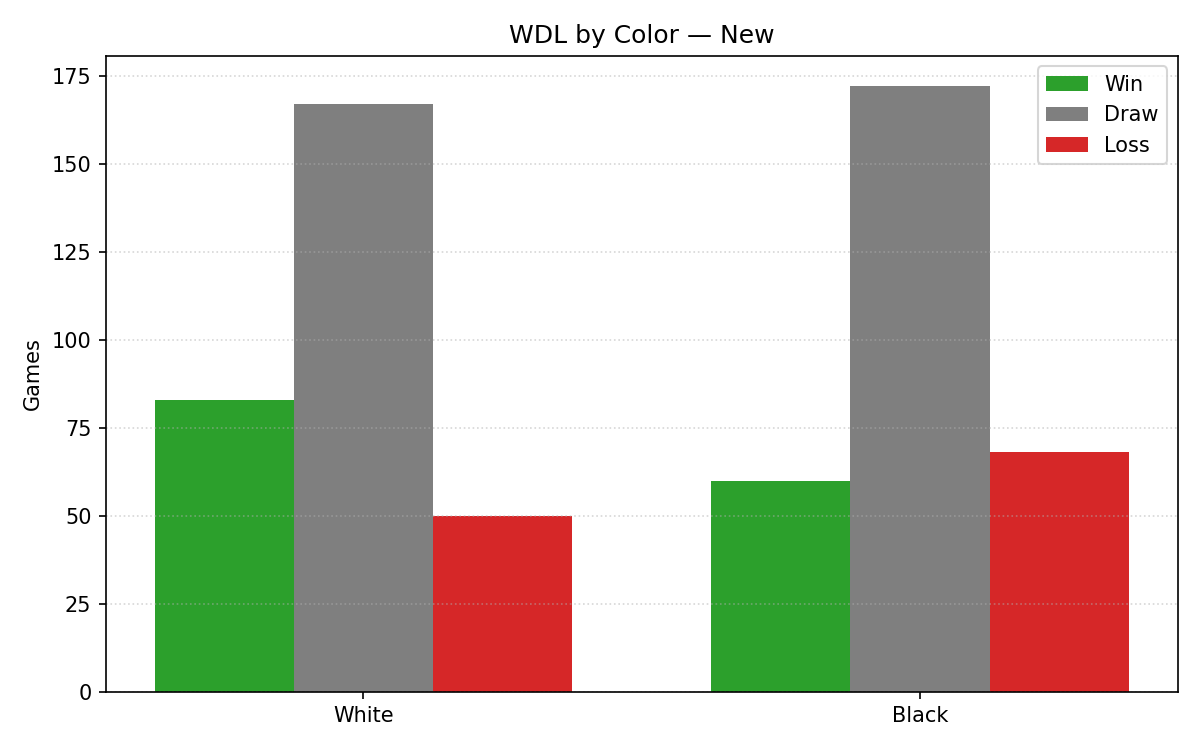

In [6]:
# =====================================================================
# 步驟 6: 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))
